# Running CROPGRO-Soybean (DSSAT) with Brazilian maturity-group cultivars

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fcoliveira-utfpr/CROPGRO_soybean_br/blob/main/calibracao_mg/produtos/notebooks/usage_example.ipynb)

This notebook shows how to use the soybean cultivars calibrated for Brazil as functions of the relative maturity group
(RMG), together with the **effective RMG and sowing date inferred from MODIS phenology** for 224 grid points
(seasons 2000/01 to 2023/24).

What it does:
1. loads the data products (coefficients by RMG, effective RMG by point and season);
2. finds the grid point closest to a location of your choice and plots its effective RMG and sowing date over time;
3. downloads daily weather for that location from NASA/POWER;
4. builds the cultivar (calibrated phenology + growth of BRS 284) and a soil profile;
5. runs DSSAT for one season and plots the phenology;
6. runs a small planning experiment (sowing date × RMG over several seasons) and plots harvest date and yield.

**Important caveats.** The cultivars are *effective* cultivars: they represent the mix of cultivars grown in a
1° cell, not a commercial cultivar. Growth coefficients are those of BRS 284 (Battisti and Sentelhas, 2019) and do not
include the genetic gain of recent cultivars, so simulated yields should be used for relative comparisons
(between sowing dates, maturity groups, seasons and regions), not as absolute yield forecasts.

**Who this notebook is for.** It was written for agronomists, consultants, students and extension agents who know
little or no programming. It runs in the browser with Google Colab: **nothing needs to be installed**. Open it in Colab,
change the few values in the cell *Your settings* (location, seasons and sowing dates), and choose
*Runtime → Run all*. Everything else (weather download, cultivar, soil, DSSAT runs and graphs) is done by the notebook.
The goal is to help planning: comparing sowing dates and maturity groups for a location, in terms of harvest date
(time left for a second crop) and water risk.

The notebook also runs locally in Jupyter on Linux and Windows (the DSSATTools package ships DSSAT executables for
both); on macOS, DSSAT must be compiled from its open-source code.

## Your settings
Change only the values below, then run all cells (*Runtime → Run all* in Colab).

In [1]:
# ---- Your settings ----------------------------------------------------------------------------------
LAT, LON = -24.86, -54.33           # location (decimal degrees; south and west are negative). Example: Santa Helena, PR
FIRST_SEASON, LAST_SEASON = 2016, 2023   # seasons to simulate, by sowing year (2016 = season 2016/17); POWER starts in 1981
SOWINGS = [(9, 20), (10, 10), (10, 30), (11, 20), (12, 10)]   # sowing dates to compare: (month, day)
RMG_SHIFTS = [-1, 0, 1]             # maturity groups to compare, relative to the effective RMG of the location
# -----------------------------------------------------------------------------------------------------

## 1. Setup

In [2]:
# Install the packages when running in Google Colab (or any environment without them).
# DSSATTools 3.0.2 is the version used to produce the data products.
import importlib.util, subprocess, sys
for pkg, pip_name in [("DSSATTools", "DSSATTools==3.0.2"), ("requests", "requests")]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=True)

In [3]:
import warnings
warnings.filterwarnings("ignore")

from datetime import date, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

from DSSATTools.crop import Soybean
from DSSATTools.filex import (Field, InitialConditions, InitialConditionsLayer, Planting, SCGeneral,
                              SCManagement, SCMethods, SCOptions, SCOutputs, SimulationControls)
from DSSATTools.run import DSSAT
from DSSATTools.soil import SoilLayer, SoilProfile
from DSSATTools.weather import WeatherRecord, WeatherStation

# Plot style: light grid, no top/right spines
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "figure.dpi": 110, "axes.titlelocation": "left",
                     "axes.titleweight": "bold"})
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"

/Users/coted-sh/Python/DSSAT/calibracao_mg/.venv/lib/python3.11/site-packages/DSSATTools/__init__.py:105: DeprecationWarning: DSSATTools version 3.0.0 is a major upgrade and will not be backwards compatible with previous versions. If you are running code that was developed  using a previous DSSATTools version, then install DSSATTools version 2.1.6
  warnings.warn(


## 2. Data products

In [4]:
# Folder with the data products. When the notebook runs inside the repository, the files are read locally;
# otherwise they are downloaded from the repository (set REPO_RAW to the raw URL of the 'produtos/dados' folder).
LOCAL_DIR = Path("../dados")
REPO_RAW = "https://raw.githubusercontent.com/fcoliveira-utfpr/CROPGRO_soybean_br/main/calibracao_mg/produtos/dados/"

def read_product(name):
    """Read a CSV data product from the local folder or, if absent, from the repository."""
    path = LOCAL_DIR / name
    return pd.read_csv(path if path.exists() else REPO_RAW + name)

theta = read_product("theta_rmg.csv")                     # coefficients by RMG (median and 90% interval)
points = read_product("coefficients_point.csv")           # one row per grid point
seasons = read_product("coefficients_point_season.csv")   # one row per point and season
print(f"{len(points)} grid points, {len(seasons)} point-seasons")
theta.head()

224 grid points, 4030 point-seasons


,rmg,csdl,ppsen,em-fl,fl-sd,sd-pm,r1ppo,csdl_q05,ppsen_q05,em-fl_q05,fl-sd_q05,sd-pm_q05,r1ppo_q05,csdl_q95,ppsen_q95,em-fl_q95,fl-sd_q95,sd-pm_q95,r1ppo_q95
0,5.0,12.8780,0.2278,21.0685,13.8810,25.8553,0.9478,12.8119,0.2160,20.3112,11.8974,25.0,0.8651,13.0729,0.2404,22.8792,15.5139,27.5026,1.0105
1,5.1,12.8535,0.2291,21.4373,13.7286,25.8174,0.9435,12.7893,0.2176,20.6892,11.8317,25.0,0.8645,13.0471,0.2401,23.2192,15.2837,27.3880,1.0032
2,5.2,12.8290,0.2304,21.8062,13.5761,25.7796,0.9391,12.7668,0.2191,21.0673,11.7660,25.0,0.8639,13.0199,0.2405,23.5533,15.0511,27.2773,0.9959
3,5.3,12.8045,0.2316,22.1750,13.4237,25.7417,0.9347,12.7441,0.2207,21.4454,11.7160,25.0,0.8633,12.9939,0.2409,23.9125,14.8202,27.1601,0.9887
4,5.4,12.7799,0.2329,22.5439,13.2712,25.7038,0.9304,12.7212,0.2222,21.8234,11.6641,25.0,0.8615,12.9680,0.2412,24.2985,14.5925,27.0335,0.9814


### Phenological coefficients as functions of the RMG
Lines are posterior medians and bands the 90% credible intervals of the Bayesian calibration.

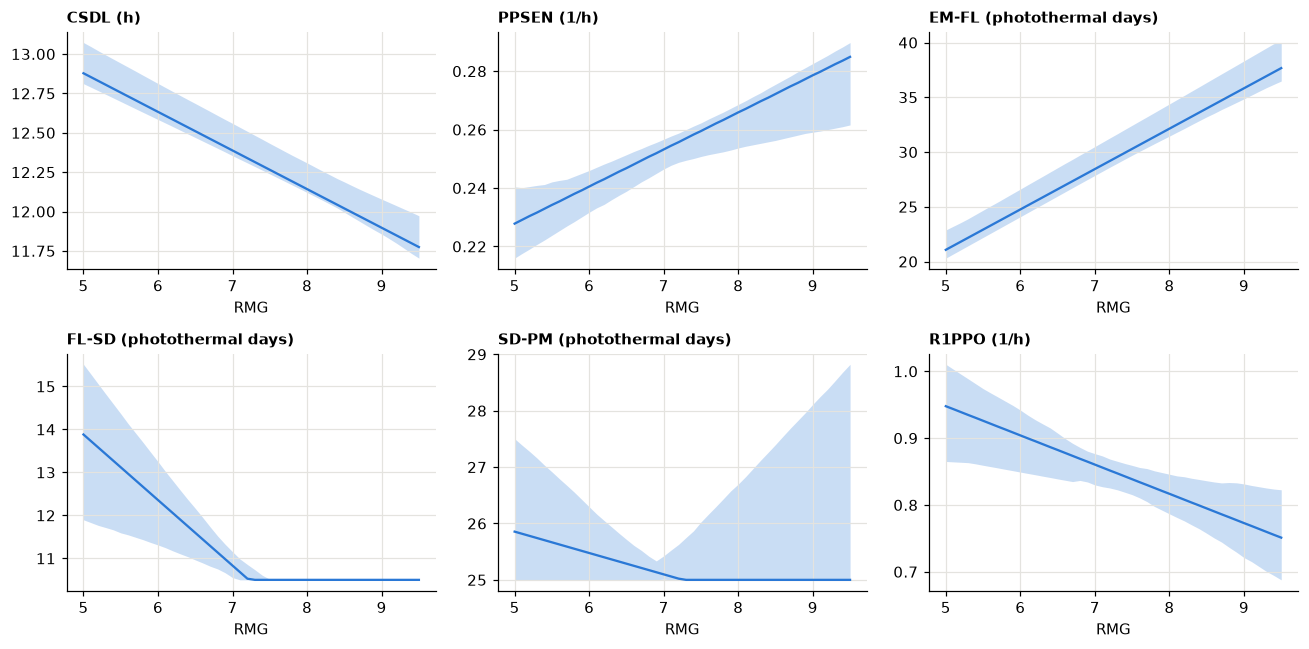

In [5]:
coefs = [("csdl", "CSDL (h)"), ("ppsen", "PPSEN (1/h)"), ("em-fl", "EM-FL (photothermal days)"),
         ("fl-sd", "FL-SD (photothermal days)"), ("sd-pm", "SD-PM (photothermal days)"), ("r1ppo", "R1PPO (1/h)")]
fig, axs = plt.subplots(2, 3, figsize=(12, 6))
for ax, (k, label) in zip(axs.ravel(), coefs):
    ax.fill_between(theta.rmg, theta[f"{k}_q05"], theta[f"{k}_q95"], color=BLUE, alpha=0.25, linewidth=0)
    ax.plot(theta.rmg, theta[k], color=BLUE)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("RMG")
fig.tight_layout()

## 3. Choose a location

In [6]:
# Nearest grid point (the location is set in "Your settings") with satellite-derived effective RMG
dist = np.hypot(points.lat - LAT, (points.lon - LON) * np.cos(np.radians(LAT)))
pt = points.loc[dist.idxmin()]
print(f"Nearest grid point: lat {pt.lat}, lon {pt.lon}, elevation {pt.elevation_m:.0f} m, region {pt.region}")
print(f"Effective RMG: mean {pt.rmg_mean:.2f}, median of the harvests 2021-2024 {pt.rmg_recent:.2f}, "
      f"trend {pt.rmg_trend_per_decade:+.2f} per decade")
print(f"Cultivar code in SBGRO048_BR.CUL: {pt.cultivar_id}")
# Soil texture classes of the soybean area in the 1° cell (MapBiomas); the dominant one is used below
soil_frac = {"clay": pt.soil_clay, "sandy_clay": pt.soil_sandy_clay, "sandy_loam": pt.soil_sandy_loam}
SOIL = max(soil_frac, key=soil_frac.get)
print("Soil fractions:", {k: round(v, 2) for k, v in soil_frac.items()}, "-> dominant:", SOIL)

Nearest grid point: lat -25.5, lon -54.5, elevation 231 m, region PR/SP/MS
Effective RMG: mean 6.35, median of the harvests 2021-2024 6.43, trend +0.15 per decade
Cultivar code in SBGRO048_BR.CUL: BR0047
Soil fractions: {'clay': np.float64(0.75), 'sandy_clay': np.float64(0.25), 'sandy_loam': np.float64(0.0)} -> dominant: clay


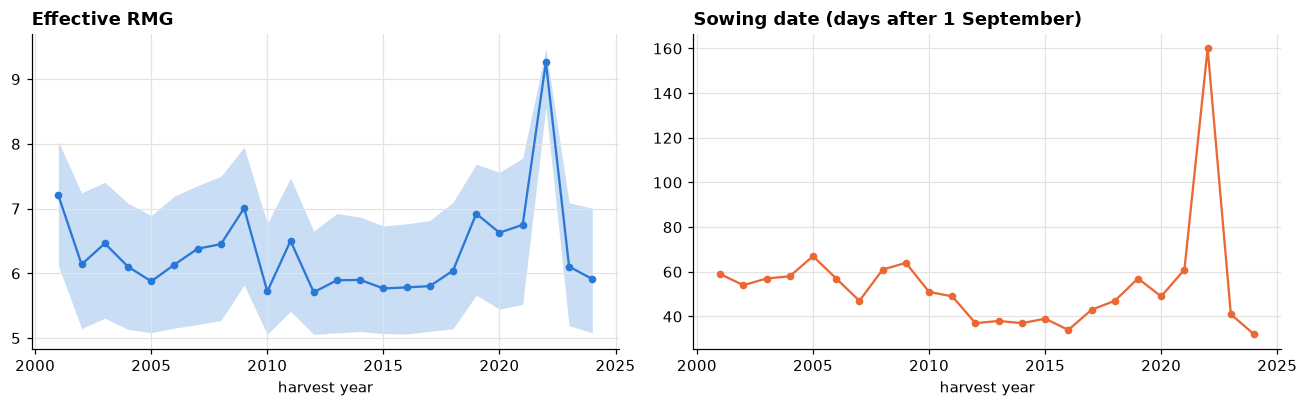

In [7]:
# Effective RMG and sowing date by season at this point (posterior median and 90% interval)
s = seasons[(seasons.lon == pt.lon) & (seasons.lat == pt.lat)].sort_values("harvest_year")
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].fill_between(s.harvest_year, s.rmg_q05, s.rmg_q95, color=BLUE, alpha=0.25, linewidth=0)
axs[0].plot(s.harvest_year, s.rmg_q50, "o-", color=BLUE, ms=4)
axs[0].set_title("Effective RMG"); axs[0].set_xlabel("harvest year")
sow = pd.to_datetime(s.sowing_date)
axs[1].plot(s.harvest_year, sow.dt.dayofyear.where(sow.dt.dayofyear > 180, sow.dt.dayofyear + 365) - 244,
            "o-", color=ORANGE, ms=4)
axs[1].set_title("Sowing date (days after 1 September)"); axs[1].set_xlabel("harvest year")
fig.tight_layout()

## 4. Daily weather from NASA/POWER

In [8]:
def nasa_power(lat, lon, start, end):
    """Download daily weather from NASA/POWER (agroclimatology community) and return a DataFrame."""
    url = ("https://power.larc.nasa.gov/api/temporal/daily/point?parameters="
           "T2M_MAX,T2M_MIN,PRECTOTCORR,ALLSKY_SFC_SW_DWN,T2MDEW,WS2M&community=AG"
           f"&longitude={lon}&latitude={lat}&start={start:%Y%m%d}&end={end:%Y%m%d}&format=JSON")
    r = requests.get(url, timeout=300)
    r.raise_for_status()
    js = r.json()
    df = pd.DataFrame(js["properties"]["parameter"])
    df.index = pd.to_datetime(df.index, format="%Y%m%d")
    df = df.replace(-999.0, np.nan).interpolate(limit=5).ffill().bfill()
    return df, js["geometry"]["coordinates"][2]   # elevation of the POWER cell (m)

def weather_station(df, lat, lon, elev):
    """Convert the POWER table into a DSSAT weather station (wind from m/s to km/day)."""
    recs = [WeatherRecord(date=d.date(), srad=round(r.ALLSKY_SFC_SW_DWN, 1), tmax=round(r.T2M_MAX, 1),
                          tmin=round(min(r.T2M_MIN, r.T2M_MAX), 1), rain=round(max(r.PRECTOTCORR, 0), 1),
                          dewp=round(min(r.T2MDEW, r.T2M_MIN + 2), 1), wind=round(r.WS2M * 86.4, 0))
            for d, r in df.iterrows()]
    return WeatherStation(table=recs, lat=lat, long=lon, insi="POWR", elev=elev, refht=2, wndht=2)

wx, elev = nasa_power(LAT, LON, date(FIRST_SEASON, 7, 1), date(LAST_SEASON + 1, 6, 30))
station = weather_station(wx, LAT, LON, elev)
print(f"{len(wx)} days of weather, elevation {elev:.0f} m")

2922 days of weather, elevation 257 m


**Note on the weather source.** The coefficients were calibrated and the effective RMG inferred with the Brazilian Daily
Weather Gridded Data (BR-DWGD, Xavier et al., 2022), and NASA/POWER is used here only because it is available
worldwide through a simple API. The two sources can differ: at the example point, NASA/POWER has about 12% less rainfall
from October to March than BR-DWGD (2016-2024), which makes the simulated water limitation stronger. In Brazil, prefer
BR-DWGD when possible.

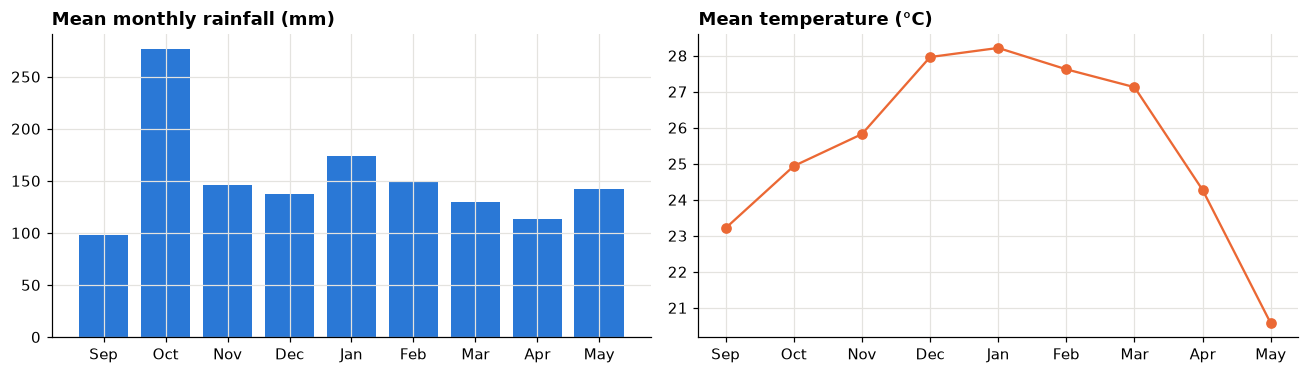

In [9]:
# Monthly rainfall and mean temperature of the downloaded period
m = wx.resample("MS").agg({"PRECTOTCORR": "sum", "T2M_MAX": "mean", "T2M_MIN": "mean"})
clim = m.groupby(m.index.month).mean()
order = [9, 10, 11, 12, 1, 2, 3, 4, 5]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
axs[0].bar(range(len(order)), clim.loc[order, "PRECTOTCORR"], color=BLUE)
axs[0].set_title("Mean monthly rainfall (mm)")
axs[1].plot(range(len(order)), (clim.loc[order, "T2M_MAX"] + clim.loc[order, "T2M_MIN"]) / 2, "o-", color=ORANGE)
axs[1].set_title("Mean temperature (°C)")
for ax in axs:
    ax.set_xticks(range(len(order)), ["Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May"])
fig.tight_layout()

## 5. Cultivar and soil

The cultivar combines the calibrated phenology (six coefficients as functions of the RMG; R1PPO belongs to the
ecotype) with the growth coefficients of BRS 284 (Battisti and Sentelhas, 2019, Table S2). The base generic cultivar
and ecotype are those of the nearest integer maturity group. This is the same construction used to produce the
`SBGRO048_BR.CUL` and `SBGRO048_BR.ECO` files, which can be used directly in DSSAT.

In [10]:
# Growth coefficients of BRS 284 (Battisti and Sentelhas, 2019, Table S2), common to all maturity groups
GROWTH = {"lfmax": 1.12, "slavr": 340, "sizlf": 185, "xfrt": 1.0, "wtpsd": 0.21, "sfdur": 23,
          "sdpdv": 2.3, "podur": 12, "thrsh": 74, "sdpro": 0.4, "sdlip": 0.2}
# Flowering-to-pod (FL-SH) and flowering-to-end-of-leaf-expansion (FL-LF) durations by maturity group of that study
FLSH_FLLF = {5.8: (6.0, 24.0), 6.8: (6.5, 26.0), 7.8: (6.5, 26.0)}

def phenology(rmg):
    """Interpolate the calibrated phenological coefficients (posterior median) at a given RMG."""
    return {k: float(np.interp(rmg, theta.rmg, theta[k])) for k, _ in coefs}

def make_cultivar(rmg):
    """Build a DSSATTools Soybean cultivar for a given RMG."""
    mg = int(np.clip(round(rmg), 5, 9))
    c = Soybean(f"99000{mg}")                      # generic cultivar of the nearest integer maturity group
    ph = phenology(rmg)
    for k in ["csdl", "ppsen", "em-fl", "fl-sd", "sd-pm"]:
        c[k] = ph[k]
    for k, v in GROWTH.items():
        c[k] = v
    flsh, fllf = FLSH_FLLF[min(FLSH_FLLF, key=lambda x: abs(x - rmg))]
    c["fl-sh"], c["fl-lf"] = flsh, fllf
    c["eco#"]["r1ppo"] = ph["r1ppo"]               # photoperiod sensitivity after flowering (ecotype)
    c["eco#"]["fl-vs"] = 26.0                      # as in Battisti and Sentelhas (2019)
    c["eco#"]["rhght"] = 1.0
    return c

print({k: round(v, 3) for k, v in phenology(pt.rmg_recent).items()})

{'csdl': 12.528, 'ppsen': 0.246, 'em-fl': 26.336, 'fl-sd': 11.704, 'sd-pm': 25.314, 'r1ppo': 0.885}


In [11]:
# Soil: the three profiles of Battisti and Sentelhas (2019, Table S1). Each layer group gives clay, silt, sand (%),
# saturation, drained upper limit, lower limit (cm3/cm3), bulk density (g/cm3) and saturated conductivity (mm/h).
SOILS = {
    "clay":       [(75, 16, 9, .578, .458, .296, 1.15, 34), (77, 15, 8, .582, .453, .298, 1.15, 11), (81, 12, 7, .622, .429, .284, 1.30, 53)],
    "sandy_clay": [(41, 11, 48, .438, .26, .16, 1.35, 67), (41, 11, 48, .438, .26, .16, 1.35, 30), (41, 11, 48, .389, .26, .16, 1.50, 67)],
    "sandy_loam": [(19, 2, 79, .387, .13, .07, 1.55, 150), (19, 2, 79, .387, .13, .07, 1.55, 94), (19, 2, 79, .343, .13, .07, 1.70, 150)],
}
ORG_C = {"clay": (1.16, 0.7, 0.4), "sandy_clay": (1.0, 0.6, 0.3), "sandy_loam": (0.62, 0.4, 0.2)}
TEXTURE = {"clay": "C", "sandy_clay": "SC", "sandy_loam": "SL"}
DEPTHS = [5, 15, 30, 40, 50, 60, 70, 100, 125, 150, 200]                     # layer bottoms (cm)
ROOTS = [1.00, 1.00, 0.18, 0.09, 0.05, 0.02, 0.01, 0.0, 0.0, 0.0, 0.0]        # root growth factor

def soil_layers(name):
    rows = []
    for base, srgf in zip(DEPTHS, ROOTS):
        h = 0 if base <= 15 else 1 if base <= 30 else 2
        clay, silt, _, sat, dul, ll, bd, ksat = SOILS[name][h]
        oc = ORG_C[name][h]
        rows.append(dict(slb=base, slll=ll, sdul=dul, ssat=sat, sbdm=bd, sloc=oc, slcl=clay, slsi=silt,
                         slhw=5.3, srgf=srgf, ssks=round(ksat / 10, 2), slni=round(oc / 12, 3)))
    return rows

def soil_profile(name, lat, lon):
    return SoilProfile(table=[SoilLayer(**r) for r in soil_layers(name)], name=f"BR{name[:2].upper()}000001",
                       soil_data_source="BS2019", soil_clasification=TEXTURE[name], soil_series_name=name,
                       site="Brazil", country="Brazil", lat=lat, long=lon, scom="R", salb=0.13, slu1=6.0,
                       sldr=0.60, slro=73, slnf=1.0, slpf=1.0)

def initial_conditions(name, day, fraction=0.75):
    """Soil water at the start of the simulation: lower limit + 75% of the available water."""
    return InitialConditions(pcr="SB", icdat=day, icres=0, icren=0, icrip=0, icrid=0, icrn=1, icre=1,
                             table=[InitialConditionsLayer(icbl=r["slb"], sh2o=round(r["slll"] + fraction * (r["sdul"] - r["slll"]), 3),
                                                           snh4=0.5, sno3=2.0) for r in soil_layers(name)])

## 6. One season

In [12]:
# Working folder of DSSAT. DSSAT fails to find its input files when the full path is long (about 50+ characters),
# so a short folder is used by default; set the environment variable DSSAT_RUN_DIR to choose another one.
import os, tempfile
RUN_DIR = os.environ.get("DSSAT_RUN_DIR", "/tmp/dssat_run" if os.name == "posix" else os.path.join(tempfile.gettempdir(), "dssat_run"))
dssat = DSSAT(RUN_DIR)

def simulate(rmg, sowing, soil=None, water=True):
    """Simulate one season and return the phenology dates and yield (soil: dominant soil of the point by default)."""
    soil = soil or SOIL
    start = sowing - timedelta(days=30)
    ctrl = SimulationControls(general=SCGeneral(sdate=start, nyers=1),
                              options=SCOptions(water="Y" if water else "N", nitro="N", symbi="N", co2="M"),
                              methods=SCMethods(evapo="R"),          # Priestley-Taylor evapotranspiration
                              management=SCManagement(irrig="N", ferti="N", harvs="M"),
                              outputs=SCOutputs(grout="N", waout="N", caout="N"))
    field = Field(id_field="BRXX0001", wsta=station, id_soil=soil_profile(soil, LAT, LON), flob=0,
                  fldt="DR000", fldd=0, flds=0, sltx=TEXTURE[soil], sldp=200)
    planting = Planting(pdate=sowing, ppop=28, ppoe=28, plrs=45, pldp=4)
    dssat.run_treatment(field=field, cultivar=make_cultivar(rmg), planting=planting,
                        initial_conditions=initial_conditions(soil, start), simulation_controls=ctrl, verbose=False)
    lines = dssat.output_files["Summary"].splitlines()
    i = next(k for k, l in enumerate(lines) if l.startswith("@"))
    out = dict(zip(lines[i].replace("@", " ").split(), lines[i + 1].split()))
    doy = lambda v: (pd.to_datetime(v, format="%Y%j") - pd.Timestamp(sowing)).days if v not in ("-99", None) else np.nan
    return {"rmg": rmg, "sowing": sowing, "emergence_das": doy(out.get("EDAT")), "R1_das": doy(out.get("ADAT")),
            "R7_das": doy(out.get("MDAT")), "harvest_das": doy(out.get("HDAT")),
            "yield_kg_ha": float(out.get("HWAM", "nan"))}

# Sowing date of the last season at this point (inferred from the satellite), with the recent effective RMG
last = s.iloc[-1]
sow = pd.Timestamp(last.sowing_date).date()
sow = date(LAST_SEASON + (sow.month < 7), sow.month, sow.day)
one = simulate(pt.rmg_recent, sow)
one

/Users/coted-sh/Python/DSSAT/calibracao_mg/.run/nb created.


{'rmg': np.float64(6.428),
 'sowing': datetime.date(2023, 10, 3),
 'emergence_das': 5,
 'R1_das': 37,
 'R7_das': 98,
 'harvest_das': 110,
 'yield_kg_ha': 1410.0}

Text(0.0, 1.0, 'RMG 6.4, sowing 03 Oct 2023, yield 1410 kg/ha')

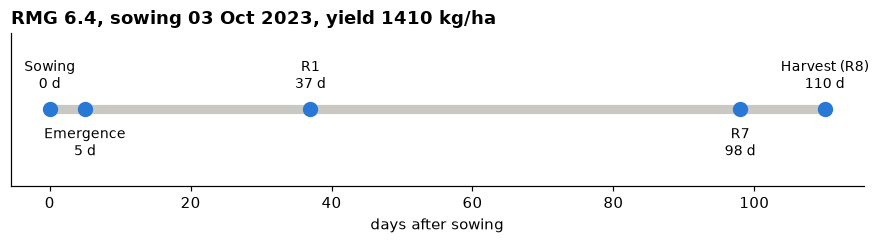

In [13]:
# Phenology of the season as a timeline (days after sowing)
stages = [("Sowing", 0), ("Emergence", one["emergence_das"]), ("R1", one["R1_das"]),
          ("R7", one["R7_das"]), ("Harvest (R8)", one["harvest_das"])]
fig, ax = plt.subplots(figsize=(10, 1.8))
ax.hlines(0, 0, stages[-1][1], color="#c9c8c3", linewidth=6)
for j, (name, d) in enumerate(stages):
    ax.plot(d, 0, "o", color=BLUE, ms=9)
    up = j % 2 == 0                                  # alternate labels above and below the line
    ax.annotate(f"{name}\n{d:.0f} d", (d, 0), textcoords="offset points", xytext=(0, 14 if up else -30),
                ha="center", fontsize=9)
ax.set_ylim(-1, 1); ax.set_yticks([]); ax.set_xlabel("days after sowing"); ax.grid(False)
ax.set_title(f"RMG {one['rmg']:.1f}, sowing {sow:%d %b %Y}, yield {one['yield_kg_ha']:.0f} kg/ha")

## 7. A planning experiment: sowing date × maturity group

For each season, the model is run with the recent effective RMG of the point and with cultivars one unit earlier and
later, for five sowing dates. The **harvest date** shows how much of the rainy season is left for a second crop, and
the **water-limited yield** (relative to the potential yield of the same cultivar and date) shows the water risk.
This takes a few minutes (each simulation takes about 1-2 s).

In [14]:
rmg0 = round(pt.rmg_recent * 2) / 2                 # effective RMG of the point, rounded to 0.5
RMGS = [float(np.clip(rmg0 + d, 5.0, 9.5)) for d in RMG_SHIFTS]   # sowing dates and RMG shifts come from "Your settings"
rows = []
for season in range(FIRST_SEASON, LAST_SEASON + 1):
    for rmg in RMGS:
        for mo, dy in SOWINGS:
            sowing = date(season, mo, dy)
            yw = simulate(rmg, sowing, water=True)
            yp = simulate(rmg, sowing, water=False)
            rows.append({**yw, "season": season, "yp_kg_ha": yp["yield_kg_ha"]})
grid = pd.DataFrame(rows)
grid["harvest_date"] = pd.to_datetime(grid.sowing) + pd.to_timedelta(grid.harvest_das, unit="D")
# harvest date as days after 1 January of the harvest year (negative values = December harvests)
grid["harvest_doy"] = (grid.harvest_date - pd.to_datetime(grid.harvest_date.dt.year.astype(str) + "-01-01")).dt.days
grid.loc[grid.harvest_date.dt.month > 7, "harvest_doy"] -= 365
grid["yw_yp"] = (grid.yield_kg_ha / grid.yp_kg_ha).clip(upper=1)
grid["sowing_label"] = pd.to_datetime(grid.sowing).dt.strftime("%d %b")
grid.groupby(["rmg", "sowing_label"], sort=False)[["harvest_das", "yield_kg_ha", "yw_yp"]].median().round(2)

harvest_das  yield_kg_ha  yw_yp
rmg sowing_label                                 
5.5 20 Sep              102.5       1620.5   0.45
    10 Oct              104.5       1516.0   0.49
    30 Oct              108.0       1679.5   0.47
    20 Nov              103.0       1784.5   0.43
    10 Dec               97.5       1988.0   0.50
6.5 20 Sep              113.5       1802.5   0.52
    10 Oct              118.0       1764.0   0.56
    30 Oct              119.0       1858.0   0.49
    20 Nov              112.0       1997.0   0.49
    10 Dec              106.0       1981.0   0.50
7.5 20 Sep              129.0       1402.0   0.52
    10 Oct              135.5       1558.5   0.57
    30 Oct              129.5       1824.0   0.52
    20 Nov              122.5       1913.5   0.52
    10 Dec              115.0       2529.0   0.65

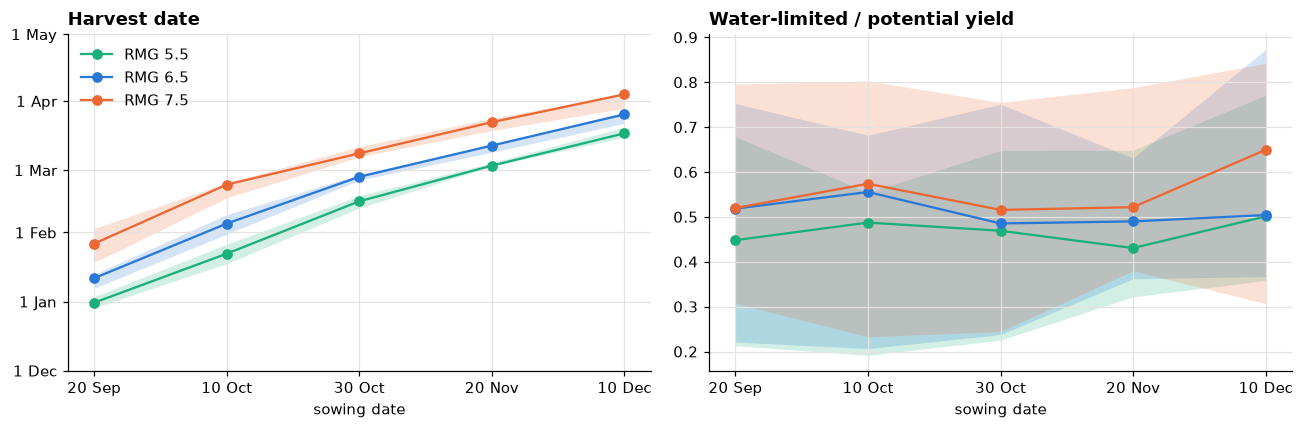

In [15]:
# Harvest date and relative water-limited yield by sowing date, for three maturity groups (median and interquartile range)
palette = [GREEN, BLUE, ORANGE, "#e87ba4", "#6250d6"]
colors = dict(zip(RMGS, palette))
labels = [pd.Timestamp(date(2001, mo, dy)).strftime("%d %b") for mo, dy in SOWINGS]
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for rmg in RMGS:
    g = grid[grid.rmg == rmg].groupby("sowing_label", sort=False)
    for ax, col in zip(axs, ["harvest_doy", "yw_yp"]):
        q = g[col].quantile([0.25, 0.5, 0.75]).unstack().reindex(labels)
        ax.fill_between(range(len(labels)), q[0.25], q[0.75], color=colors[rmg], alpha=0.2, linewidth=0)
        ax.plot(range(len(labels)), q[0.5], "o-", color=colors[rmg], label=f"RMG {rmg:.1f}")
for ax in axs:
    ax.set_xticks(range(len(labels)), labels); ax.set_xlabel("sowing date")
axs[0].set_title("Harvest date")
ticks = [-31, 0, 31, 59, 90, 120]                        # 1 Dec, 1 Jan, 1 Feb, 1 Mar, 1 Apr, 1 May
axs[0].set_yticks(ticks, ["1 Dec", "1 Jan", "1 Feb", "1 Mar", "1 Apr", "1 May"])
axs[1].set_title("Water-limited / potential yield")
axs[0].legend(frameon=False)
fig.tight_layout()

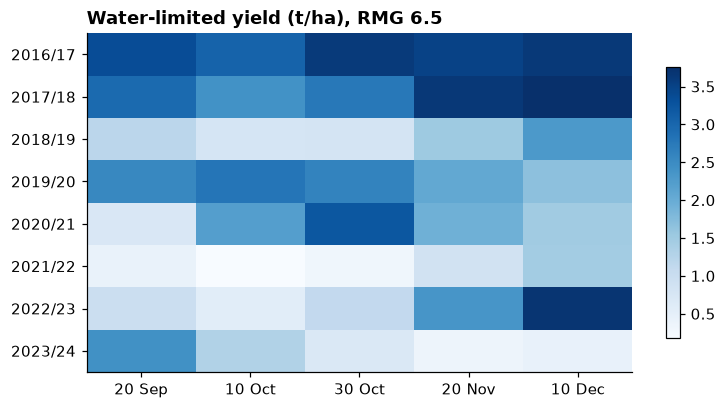

In [16]:
# Year-to-year variation of the water-limited yield for the recent effective RMG
g = grid[grid.rmg == rmg0].pivot_table(index="season", columns="sowing_label", values="yield_kg_ha")[labels]
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(g.values / 1000, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(labels)), labels); ax.set_yticks(range(len(g)), [f"{y}/{str(y + 1)[2:]}" for y in g.index])
ax.set_title(f"Water-limited yield (t/ha), RMG {rmg0:.1f}"); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)

## 8. Using the DSSAT files directly

The files `SBGRO048_BR.CUL` and `SBGRO048_BR.ECO` contain the same cultivars and can be used in any DSSAT 4.8
installation: copy them to the folder of the experiment (or to `DSSAT48/Genotype`, renaming them to
`SBGRO048.CUL`/`SBGRO048.ECO` after making a backup of the originals) and use the cultivar code in the FileX:

* `BRG050` … `BRG095`: generic Brazilian cultivars for RMG 5.0 to 9.5 (step 0.5);
* `BR0001` … `BR0224`: one cultivar per grid point, with the effective RMG of the harvests 2021-2024
  (the code of each point is in `coefficients_point.csv`, column `cultivar_id`).

The outputs of DSSAT with these files were verified to be identical to those of the cultivar built in this notebook.